# Ducky Dataset Phase Retrieval

> Georgios Varnavides | Jan 12 2025  
>
> Sample: graphene substrate ducky  
> Sampling conditions: 4 A step-size  
> Imaging conditions: 80 kV, 20 mrad, 500 A defocus  
> Dose conditions: 1e5 e/A2  

A simulated duck-shaped phase object on graphene, scanned with a 4 A step and with descan. We
compare the six kernels with upsampling, and fit the defocus and rotation angle three ways.

In [1]:
# %load_ext autoreload 
# %autoreload 2

In [2]:
import quantem as em
import numpy as np

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

We load the simulated dataset and set the conditions it was simulated with.

In [3]:
dataset = em.core.io.load("../../data/ducky_20mrad_500A-df_4A-step.zip")
dataset

Dataset(shape=(41, 41, 200, 200), dtype=float32, name='4D-STEM dataset')
  sampling: [4.         4.         1.04392901 1.04392901]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

In [4]:
energy = 80e3
semiangle_cutoff = 20
defocus = 500
rotation_angle_deg = -15

## Finite dose

The dataset is noise-free, so we draw Poisson counts at 1e5 electrons per square Angstrom:

In [5]:
def add_poisson_noise(
    dataset,
    electrons_per_area,
):
    if electrons_per_area == np.inf:
        return dataset
    electrons_per_probe = electrons_per_area * dataset.sampling[:2].prod()
    
    dataset_noisy = dataset.copy()
    dataset_noisy.array = np.random.poisson(dataset.array * electrons_per_probe)
    return dataset_noisy

In [6]:
np.random.seed(2025)
noisy_dataset = add_poisson_noise(
    dataset,
    1e5
)

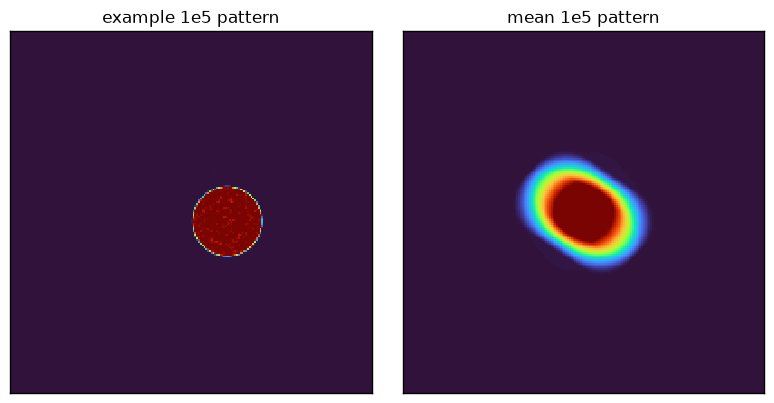

In [7]:
# notice the descan!
em.visualization.show_2d(
    [
        noisy_dataset[0,0].array,
        noisy_dataset.mean((0,1)),
    ],
    title=[
        "example 1e5 pattern","mean 1e5 pattern"
    ],
    power=0.5,
    cmap='turbo'
);

A single pattern is a sharp bright-field disk, but the mean is smeared along a diagonal, since the
disk moves across the detector as the probe scans. `from_dataset4d` fits this descan and shifts
each pattern back.

## Reconstruction

We start from the known defocus and rotation angle. A `"defocus"` entry in `aberration_coefs` is the
same as minus `C10`.

In [8]:
direct_ptycho = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    noisy_dataset,
    energy=energy,
    semiangle_cutoff=semiangle_cutoff,
    rotation_angle=rotation_angle_deg,
    aberration_coefs={"defocus":defocus},
    # device='gpu',
)

`_reconstruct_all_permutations` runs all six kernels with the same settings. The 4 A step
undersamples the bright field, so we upsample twice:

100%|██████████| 6/6 [00:16<00:00,  2.74s/it]


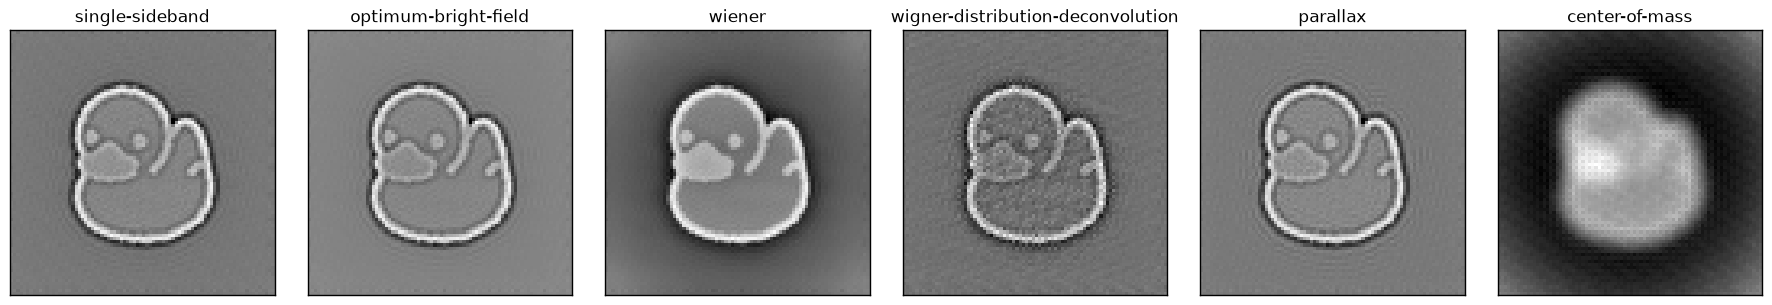

In [9]:
kwargs = {
    "title":["single-sideband","optimum-bright-field","wiener","wigner-distribution-deconvolution","parallax","center-of-mass"],
    "norm":"minmax",
    "axsize":(3,3),
}

recons = direct_ptycho._reconstruct_all_permutations(
    upsampling_factor=2,
)

em.visualization.show_2d(
    recons,
    **kwargs
);

The deconvolution kernels and parallax recover the duck and its outline. Wiener also keeps the mean
phase inside the duck, which the others fade. WDD is the noisiest at this dose, and the center of
mass is a low-pass of the object.

## Parameter estimation

When the hyperparameters are not known, they can be estimated from the data, as
`ptycho_direct_06_hyperparameters` covers in detail. Here three ways agree. First, Bayesian
optimization of the defocus and rotation angle. The `rms_gradient` loss rewards a sharp
parallax reconstruction:

Best trial: 88. Best value: -0.0113611: 100%|██████████| 250/250 [01:08<00:00,  3.64it/s]


Optimized state:

 HyperparameterState(
  initial_aberrations={'C10': -500.0},
  initial_rotation_angle_deg=-15,
  optimized_aberrations={'C10': -531.2292963079658},
  optimized_rotation_angle_deg=-15.070174696537915,
)


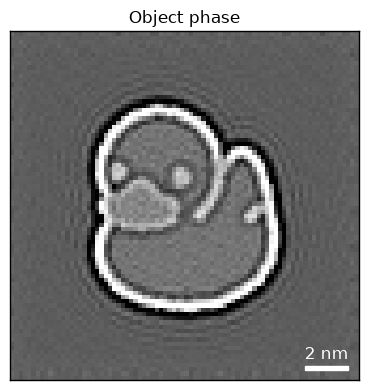

In [10]:
# Optimize defocus with optuna
direct_ptycho = direct_ptycho.optimize_hyperparameters(
    aberration_coefs={
        "C10":em.diffractive_imaging.OptimizationParameter(-1000,0),
    },
    rotation_angle=em.diffractive_imaging.OptimizationParameter(-30,0),
    n_trials=250,
    deconvolution_kernel='parallax',
    loss='rms_gradient'
)

direct_ptycho.reconstruct(
    deconvolution_kernel='parallax',
    upsampling_factor=2,
    verbose=False,
).visualize(
    show_obj_fft=False,
)

It finds `C10` = -531 A at -15.07 degrees, against the true -500 A and -15 degrees.

The cross-correlation fit, starting from zero aberrations and rotation:

Aligning (reference): 100%|██████████| 5/5 [00:01<00:00,  2.92it/s]


Optimized state:

 HyperparameterState(
  initial_aberrations={'C10': -500.0},
  initial_rotation_angle_deg=-15,
  optimized_aberrations={'C10': -525.510498046875, 'C12': 0.8572391271591187, 'phi12': -0.07660181820392609},
  optimized_rotation_angle_deg=-15.004491806030273,
)


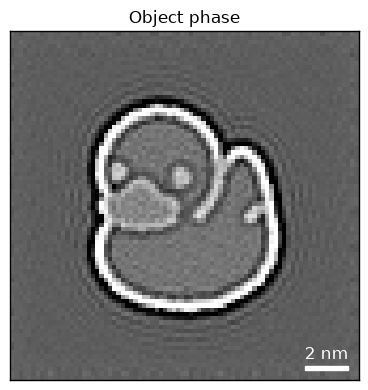

In [11]:
# reference fit from scratch (note the aberration_coeffs and rotation_angle arguments overriding init values)
direct_ptycho = direct_ptycho.fit_hyperparameters_cross_correlation(
    alignment_method='reference',
    bin_factors=(3,2,1,1,1),

    # reset aberrations and rotation to prove it can find it from scratch.
    aberration_coefs = {'C10':0.0,'C12':0.0,'phi12':0.0},
    rotation_angle= 0.0,
)

direct_ptycho.reconstruct(
    deconvolution_kernel='parallax',
    upsampling_factor=2,
    verbose=False,
).visualize(
    show_obj_fft=False,
)

It finds -526 A at -15.00 degrees. Finally, the gradient fit of the residual, starting from that
result:

Optimized state:

 HyperparameterState(
  initial_aberrations={'C10': -500.0},
  initial_rotation_angle_deg=-15,
  optimized_aberrations={'C10': -478.7337951660156, 'C12': 0.4279691278934479, 'phi12': -0.07659568637609482},
  optimized_rotation_angle_deg=-14.999224662780762,
)


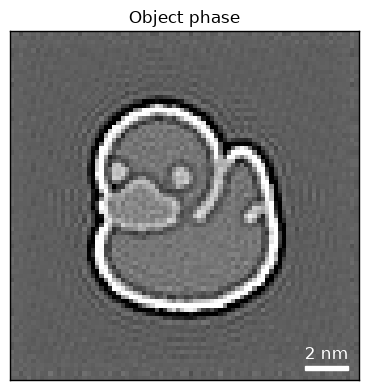

In [12]:
# refine by gradient descent on the residual, starting from the cross-correlation fit
direct_ptycho = direct_ptycho.fit_hyperparameters_gradient(
    ("C10", "C12", "phi12", "rotation_angle"),
    deconvolution_kernel='obf',
    verbose=True,
)

direct_ptycho.reconstruct(
    deconvolution_kernel='parallax',
    upsampling_factor=2,
    verbose=False,
).visualize(
    show_obj_fft=False,
)

It moves the defocus to -479 A. All three estimates are within about 30 A of the truth, a third of
the depth of field $\lambda / \alpha^2 \approx$ 100 A, and give the same reconstruction.